# Smog Album: The Wind That Sweeps the Smog

Issue #49. Follows [notebook-guide.md](../docs/notebook-guide.md) and [data-guide.md](../docs/data-guide.md). The album plays nell-v2's music (its loops, and the way the air muffles them) over three cities of three different regions (user, 2026-11-15).

**What this notebook decides:** which three cities and which hours. The air must keep changing, which is the point of the album (user, 2026-11-15): each song runs from clear air through one to three rounds of smog rolling in and clearing, each long enough to follow, not flickering back and forth, back to clear air. And the smog must flow (user, 2026-11-15): carried across the map by the wind, not thickening and thinning in place.

**How a turn is found:** with the app's own rules (`src/features/tracks/domain/smog.js`, mirrored in section 4): each cell's PM2.5 becomes a fog of 0 to 1; the haze is the fog over the city's own cell (user, 2026-11-15: the air right over the city), the middle of the 33 × 33 cells (±4°) the map draws; the smog rolls in when the haze rises past 0.5 and is swept out when it falls below 0.3.

**How much data:** a song plays four to seven days of hours in about a minute, a third to a half of a second an hour, so every hour is used, and nothing finer: hourly means on GEOS-CF's 0.25° grid, only over each candidate's box and only in its window.

**Steps:**

1. EIC's message about PM2.5 (5151).
2. The candidate episodes: heavy PM2.5 that comes and goes, in many regions.
3. Each candidate's hourly haze, and its turns.
4. The pick: in each candidate the stretch whose air changes the most; then one song per region, those whose fog flows fastest.
5. The three songs exported as tracks.

> The cities, the episodes and the rule that picks them are **ours**. EIC 5151 shows the whole world's PM2.5 and names no place.

Run with `npm run notebook`. The first run reads about 300 days of 33 × 33 cell boxes from NASA's OPeNDAP server (about 30 MB, 10 to 15 minutes) into `data/smog/raw/screen_box/` and exports the tracks to `data/smog/tracks/`.

In [1]:
import html
import json
import re
import struct
import time
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timedelta, timezone
from pathlib import Path
from zoneinfo import ZoneInfo

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/smog/raw")
for sub in ("api", "screen_box", "natural_earth"):
    (RAW / sub).mkdir(parents=True, exist_ok=True)
TRACKS = Path("../data/smog/tracks")

# GEOS-CF v1, the hourly surface air quality collection, served by OPeNDAP so a box can be read alone.
OPENDAP = "https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/aqc_tavg_1hr_g1440x721_v1"
VARIABLE = "pm25_rh35_gcc"                 # PM2.5 at 35 % relative humidity, µg/m³
FIRST_HOUR = datetime(2018, 1, 1, 0, 30, tzinfo=timezone.utc)  # hourly means, stamped mid-hour
GRID_DEG = 0.25
LON_POINTS = 1440
BOX = 16                                   # cells each way from the city's cell: ±4°, 33 × 33 cells
HOURS_PER_REQUEST = 24                     # the server reads one file per hour
PARALLEL = 6
RETRIES = 5
TIMEOUT_SEC = 120

NATURAL_EARTH_50M = "https://naciscdn.org/naturalearth/50m/cultural"
CREDIT = f"Source: GEOS-CF v1 (NASA GMAO), surface PM2.5 ({VARIABLE}), hourly means"


def download(name, url):
    path = RAW / name
    if not path.exists():
        r = requests.get(url, timeout=TIMEOUT_SEC)
        r.raise_for_status()
        path.write_bytes(r.content)
    return path


def svs_page(page_id):
    path = RAW / "api" / f"{page_id}.json"
    if not path.exists():
        path.write_text(requests.get(f"https://svs.gsfc.nasa.gov/api/{page_id}", timeout=60).text)
    return json.loads(path.read_text())


def plain(text):
    return re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", text or ""))).strip()


def source_note(ax, text=CREDIT, y=-38):
    ax.annotate(text, (0, 0), (0, y), xycoords="axes fraction", textcoords="offset points", fontsize=8, color="gray")

## 1. Links

### 1.1 EIC page and what it cites

Built from the SVS API.

In [2]:
PAGES = [5151]


def cited(page_id):
    out = []
    for d in svs_page(page_id).get("datasets", []):
        name = d["name"] or "unnamed dataset"
        out.append(f"[{name}]({d['url'].replace('http://', 'https://')})" if d.get("url") else f"{name}, no link")
    return "<br>".join(out) or "none"


rows = ["| SVS page | SVS API | Cited source |", "| --- | --- | --- |"]
for i in PAGES:
    rows.append(f"| [{i} {svs_page(i)['title']}](https://svs.gsfc.nasa.gov/{i}/) | "
                f"[api/{i}](https://svs.gsfc.nasa.gov/api/{i}) | {cited(i)} |")
display(Markdown("\n".join(rows)))

| SVS page | SVS API | Cited source |
| --- | --- | --- |
| [5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) | [api/5151](https://svs.gsfc.nasa.gov/api/5151) | [GEOS-CF](https://portal.nccs.nasa.gov/datashare/gmao/geos-cf/v2/) |

Gallery path: EIC Dashboards → [Air Quality Dashboard](https://svs.gsfc.nasa.gov/gallery/air-quality-dashboard/) → Models: Air Quality → 5151 (also under the Earth Now Dashboard and Daily Visualizations).

### 1.2 What this notebook downloads

| Downloaded file | Dataset page | Note |
| --- | --- | --- |
| `https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/aqc_tavg_1hr_g1440x721_v1.dods?pm25_rh35_gcc[<hour>:<hour + 23>][0][<row - 16>:<row + 16>][<col - 16>:<col + 16>]`: each candidate's 33 × 33 cells (0.25°) around its city's cell, 24 hours a request, over its window | [GEOS-CF (NASA GMAO)](https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/) | Same dataset as cited, older version, public. 5151 links GEOS-CF **v2**, which starts on 2025-08-04; v1 runs from 2018-01-01 to 2026-01-02 and holds every candidate. |
| [ne_50m_admin_0_countries.zip](https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip) | [Natural Earth](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/) | Not from EIC, public domain. Map outlines for the graphs only. |

## 2. What EIC says

[5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) · source: [GEOS-CF](https://portal.nccs.nasa.gov/datashare/gmao/geos-cf/v2/)

The page is one of the Air Quality Dashboard's model views. It is regenerated regularly and shows the last two weeks of the whole world, hour by hour; its dataset entry gives no date range. Its words:

In [3]:
def captions(page_id):
    page = svs_page(page_id)
    texts = [plain(page["description"].split(" || ")[0])]
    texts += [plain(g.get("caption")) or plain(g.get("description")) for g in page["media_groups"]]
    return [t for t in texts if t]


for text in captions(5151):
    if len(text) > 100:
        display(Markdown(f"> {text}"))

> Near surface concentration of fine particular matter (PM2.5) estimated from NASA’s aerosol and weather fields produced by NASA’s GEOS-CF model.

> Near surface concentration of fine particular matter (PM2.5) estimated from NASA’s aerosol and weather fields produced by NASA’s GEOS-CF model.

> Predictions of air pollution are created using complex models that combine information about weather and the emissions, transformation, and transport of chemical species and particles. The Goddard Earth Observing System Composition Forecasting (GEOS-CF) system is a research model maintained by NASA’s Global Modeling and Assimilation Office to help scientists understand the causes and impact of air pollution. It is one of the highest resolution and most detailed models of its kind in the world, made possible through ongoing collaborations between NASA and university scientists. GEOS-CF tracks the concentrations of hundreds of gas phase chemical species and dozens of types of particles characterized by their composition and size. It is used by a wide variety of stakeholders around the world to develop new methods for improving local predictions, understanding the impact of pollution on human health, and improving the quality of NASA satellite datasets. Scientists and air quality managers carefully track the concentrations of small particulate matter because it contributes to increased risk of asthma, respiratory inflammation, and poor lung function. PM2.5 is calculated using near surface GEOS-CF fields of numerous aerosol types, temperature, and pressure. The slight pulsing that is visible reflects variations in pollution throughout the day as a result of traffic cycles and weather variations. Though small particles typically remain in the atmosphere for only a few days, they can be transported far away from source regions by large scale weather systems. In many parts of the U.S. and Europe, PM2.5 levels have decreased substantially in recent decades due to improvements in technology and regulation. However, increases in the frequency, severity, and duration of wildfires in response to climate change can put communities worldwide at risk of exposure.

> Particular matter (PM2.5) concentration colorbar with semi-transparent background, optimized for Earth Information Center content.

> See [https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/](https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/)

What the album takes from it:

- "Though small particles typically remain in the atmosphere for only a few days, they can be transported far away from source regions by large scale weather systems."

Smoke from fires, dust from deserts and winter smog over cities all arrive and leave with the weather within days. Each song is one such visit, in a different part of the world; the places and the visits are ours.

## 3. The candidates

[5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) · source: [GEOS-CF v1](https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/aqc_tavg_1hr_g1440x721_v1)

Heavy PM2.5 that comes and goes, from as many regions as possible:

- **2025**: the cities whose own cell, one hour a day (00:30 UTC) on a 1° grid, rose into heavy smog (the city's fog 0.5 or more, about 120 µg/m³) for at least two days with at least two clear days on each side, from this notebook's earlier screening of 243 capitals and major cities (commit 62360ef). Each listed once per region, at its longest or heaviest episode.
- **2019–2024**: well-known episodes in regions 2025 left out: wildfire smoke in North America, Australia, Southeast Asia and South America, and the winter smog of South Asia.

Each window runs from three days before the episode to three days after it.

In [4]:
# (city, region, lat, lon, time zone, first day of the episode (UTC), its days)
CANDIDATES = [
    ("Beijing", "Eastern Asia", 39.930838, 116.38634, "Asia/Shanghai", "2025-01-29", 4),
    ("Beijing", "Eastern Asia", 39.930838, 116.38634, "Asia/Shanghai", "2025-10-22", 4),
    ("Seoul", "Eastern Asia", 37.568295, 126.997785, "Asia/Seoul", "2025-03-22", 4),
    ("Pyongyang", "Eastern Asia", 39.021385, 125.752745, "Asia/Pyongyang", "2025-11-23", 4),
    ("Bangkok", "South-Eastern Asia", 13.751945, 100.514699, "Asia/Bangkok", "2025-01-23", 4),
    ("Jakarta", "South-Eastern Asia", -6.172472, 106.827492, "Asia/Jakarta", "2025-07-10", 4),
    ("Chiang Mai", "South-Eastern Asia", 18.79, 98.99, "Asia/Bangkok", "2024-03-25", 10),
    ("Palangka Raya", "South-Eastern Asia", -2.21, 113.92, "Asia/Jakarta", "2019-09-10", 10),
    ("New Delhi", "Southern Asia", 28.600023, 77.19998, "Asia/Kolkata", "2025-09-16", 5),
    ("New Delhi", "Southern Asia", 28.61, 77.21, "Asia/Kolkata", "2024-11-08", 9),
    ("Lahore", "Southern Asia", 31.55, 74.34, "Asia/Karachi", "2024-11-01", 9),
    ("Islamabad", "Southern Asia", 33.701942, 73.164689, "Asia/Karachi", "2025-12-02", 4),
    ("Kuwait City", "Western Asia", 29.371664, 47.976355, "Asia/Kuwait", "2025-05-16", 4),
    ("Cairo", "Northern Africa", 30.051906, 31.248022, "Africa/Cairo", "2025-01-26", 10),
    ("Cairo", "Northern Africa", 30.051906, 31.248022, "Africa/Cairo", "2025-11-26", 4),
    ("Dakar", "Western Africa", 14.717778, -17.475076, "Africa/Dakar", "2025-03-23", 5),
    ("Banjul", "Western Africa", 13.453877, -16.591702, "Africa/Banjul", "2025-03-24", 4),
    ("Johannesburg", "Southern Africa", -26.168099, 28.028064, "Africa/Johannesburg", "2025-02-28", 3),
    ("Portland", "Northern America", 45.52, -122.68, "America/Los_Angeles", "2020-09-06", 10),
    ("Seattle", "Northern America", 47.61, -122.33, "America/Los_Angeles", "2020-09-08", 8),
    ("Edmonton", "Northern America", 53.55, -113.49, "America/Edmonton", "2023-05-12", 7),
    ("New York", "Northern America", 40.71, -74.01, "America/New_York", "2023-06-03", 3),
    ("Canberra", "Australia and New Zealand", -35.28, 149.13, "Australia/Sydney", "2019-12-28", 9),
    ("Sydney", "Australia and New Zealand", -33.87, 151.21, "Australia/Sydney", "2019-12-03", 8),
    ("Porto Velho", "South America", -8.76, -63.9, "America/Porto_Velho", "2024-08-20", 10),
]
WINDOW_PAD_DAYS = 3
candidates = pd.DataFrame(CANDIDATES, columns=["city", "region", "lat", "lon", "tz", "start", "days"])
print(f"{len(candidates)} candidates in {candidates['region'].nunique()} regions")

25 candidates in 10 regions


In [5]:
def cell(lat, lon):
    return round((lat + 90) / GRID_DEG), round((lon + 180) / GRID_DEG) % LON_POINTS


def fetch(url):
    for attempt in range(RETRIES):
        try:
            r = requests.get(url, timeout=TIMEOUT_SEC)
            if r.ok and r.content.startswith(b"Dataset") and b"\nData:\n" in r.content:
                return r.content
        except requests.RequestException:
            pass
        time.sleep(5 * (attempt + 1))
    raise RuntimeError(f"GEOS-CF request failed after {RETRIES} tries: {url}")


def parse_dods(body, shape):
    # A DAP2 binary reply: the text header, "Data:\n", then the array as XDR (its length twice, big-endian float32).
    at = body.index(b"\nData:\n") + len(b"\nData:\n")
    n = struct.unpack(">I", body[at:at + 4])[0]
    assert n == np.prod(shape), (n, shape)
    return np.frombuffer(body, ">f4", count=n, offset=at + 8).reshape(shape).astype(np.float32)


def box_request(c, first):
    r, k = cell(c.lat, c.lon)
    return f"[{first}:{first + HOURS_PER_REQUEST - 1}][0][{r - BOX}:{r + BOX}][{k - BOX}:{k + BOX}]"


def box_hours(args):
    """HOURS_PER_REQUEST hours of a candidate's box from hour index `first`: [hour][row][col], cached."""
    c, first = args
    path = RAW / "screen_box" / f"{c.city.lower().replace(' ', '_')}_{c.start.replace('-', '')}_{first}.npy"
    if not path.exists():
        body = fetch(f"{OPENDAP}.dods?{VARIABLE}{box_request(c, first)}")
        np.save(path, parse_dods(body, (HOURS_PER_REQUEST, 1, 2 * BOX + 1, 2 * BOX + 1))[:, 0])
    return np.load(path)


def window(c):
    """The candidate's first hour index and its hours: from WINDOW_PAD_DAYS before the episode to as many after."""
    t0 = datetime.fromisoformat(c.start).replace(tzinfo=timezone.utc) - timedelta(days=WINDOW_PAD_DAYS, minutes=-30)
    first = round((t0 - FIRST_HOUR).total_seconds() / 3600)
    return first, (c.days + 2 * WINDOW_PAD_DAYS) * 24


jobs = [(c, s) for c in candidates.itertuples() for s in range(window(c)[0], sum(window(c)), HOURS_PER_REQUEST)]
with ThreadPoolExecutor(PARALLEL) as pool:
    chunks = list(pool.map(box_hours, jobs))
boxes, at = [], 0
for c in candidates.itertuples():
    n = window(c)[1] // HOURS_PER_REQUEST
    boxes.append(np.concatenate(chunks[at:at + n]))
    at += n
print(f"{len(jobs)} requests, {sum(len(b) for b in boxes)} hours of {2 * BOX + 1} × {2 * BOX + 1} cells")

306 requests, 7344 hours of 33 × 33 cells


## 4. Each candidate's haze and turns

The app's rules, mirrored from `src/features/tracks/domain/smog.js` (the app is the source; a change there must be made here too):

- pollution: 0 for clean air to 1 at 600 µg/m³, log-scaled in multiples of the WHO 24-hour guideline (15 µg/m³), stored as a byte (0–255)
- fog: none below pollution 0.33 (about 40 µg/m³), all of it from 0.85 (about 330 µg/m³), smoothstepped between
- haze: the fog over the city's cell, the box's middle; the smog rolls in as it rises past 0.5 and is swept out as it falls below 0.3

The values are rounded to whole µg/m³ first, as the tracks are.

In [6]:
WHO_24H_PM25, FULL_SCALE_PM25 = 15, 600
FOG_FROM, FOG_FULL = 0.33, 0.85
CLEAR_BELOW, SMOTHERED_ABOVE = 0.3, 0.5


def level_of(pm25):
    """Each value's pollution level, as a byte over 255."""
    pm25 = np.round(pm25)
    return np.round(255 * np.clip(np.log1p(pm25 / WHO_24H_PM25) / np.log1p(FULL_SCALE_PM25 / WHO_24H_PM25), 0, 1)) / 255


def city_level(frames):
    """The pollution level over the city's cell each hour."""
    return level_of(frames[:, BOX, BOX])


def fog_of(level):
    x = np.clip((level - FOG_FROM) / (FOG_FULL - FOG_FROM), 0, 1)
    return x * x * (3 - 2 * x)


def turns_of(haze):
    """Each turn as (fractional hour, clear), as turnsOf in smog.js."""
    clear = haze[0] < (CLEAR_BELOW + SMOTHERED_ABOVE) / 2
    turns = []
    for i in range(1, len(haze)):
        edge = SMOTHERED_ABOVE if clear else CLEAR_BELOW
        if (haze[i] <= edge) if clear else (haze[i] >= edge):
            continue
        clear = not clear
        turns.append((i - 1 + (edge - haze[i - 1]) / (haze[i] - haze[i - 1]), clear))
    return turns


levels = [city_level(b) for b in boxes]
hazes = [fog_of(l) for l in levels]
candidates["peak_haze"] = [h.max().round(2) for h in hazes]
candidates["turns"] = [len(turns_of(h)) for h in hazes]
candidates[["city", "region", "start", "days", "peak_haze", "turns"]]

,city,region,start,days,peak_haze,turns
0,Beijing,Eastern Asia,2025-01-29,4,1.00,6
1,Beijing,Eastern Asia,2025-10-22,4,1.00,5
2,Seoul,Eastern Asia,2025-03-22,4,0.96,12
3,Pyongyang,Eastern Asia,2025-11-23,4,1.00,8
4,Bangkok,South-Eastern Asia,2025-01-23,4,1.00,20
5,Jakarta,South-Eastern Asia,2025-07-10,4,1.00,18
6,Chiang Mai,South-Eastern Asia,2024-03-25,10,1.00,7
7,Palangka Raya,South-Eastern Asia,2019-09-10,10,1.00,26
8,New Delhi,Southern Asia,2025-09-16,5,0.97,15
9,New Delhi,Southern Asia,2024-11-08,9,1.00,6


Over the city's own cell the air swings much more than over the whole box: nearly every candidate is thick with smog at some hour, and many flicker, the smog thinning in the afternoon and returning at night.

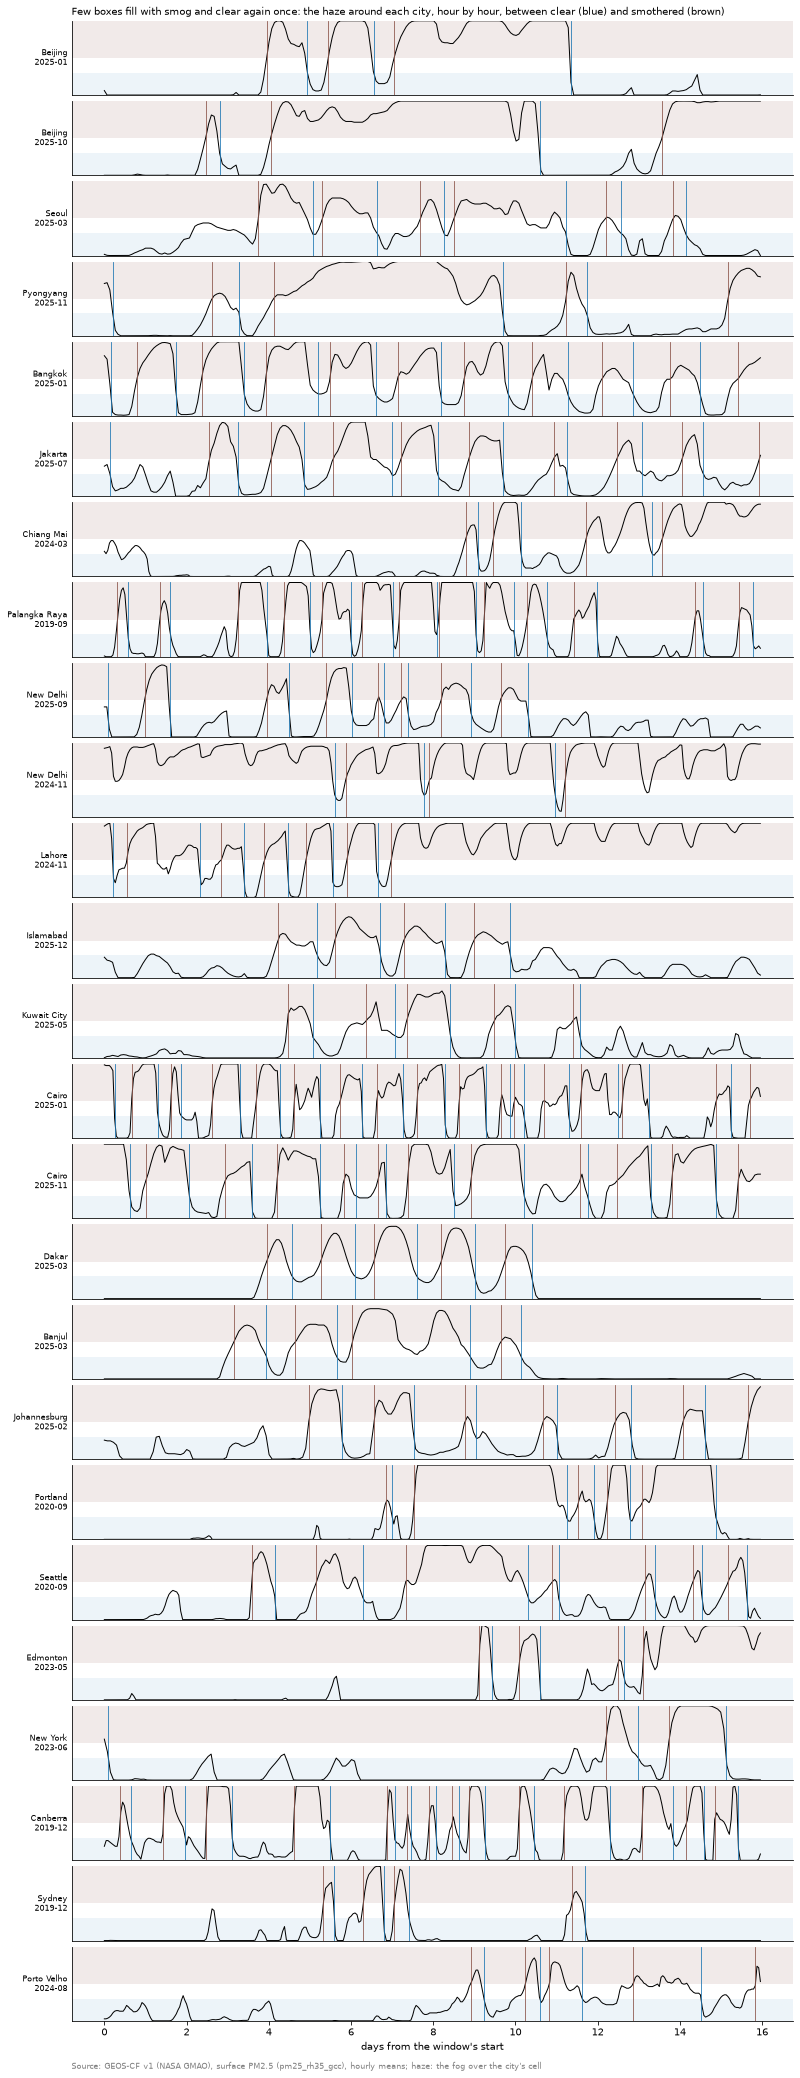

In [7]:
fig, axes = plt.subplots(len(candidates), 1, figsize=(11, 1.15 * len(candidates)), constrained_layout=True)
for ax, c, h in zip(axes, candidates.itertuples(), hazes):
    ax.plot(np.arange(len(h)) / 24, h, color="k", lw=1)
    ax.axhspan(SMOTHERED_ABOVE, 1, color="tab:brown", alpha=0.12, lw=0)
    ax.axhspan(0, CLEAR_BELOW, color="tab:blue", alpha=0.08, lw=0)
    for hour, clear in turns_of(h):
        ax.axvline(hour / 24, color="tab:blue" if clear else "tab:brown", lw=0.8)
    ax.set_ylim(0, 1); ax.set_yticks([]); ax.set_xticks([])
    ax.set_ylabel(f"{c.city}\n{c.start[:7]}", rotation=0, ha="right", va="center", fontsize=8)
axes[0].set_title("Few boxes fill with smog and clear again once: the haze around each city, hour by hour, "
                  "between clear (blue) and smothered (brown)", loc="left", fontsize=10)
axes[-1].set_xticks(range(0, 17, 2)); axes[-1].set_xlabel("days from the window's start")
source_note(axes[-1], CREDIT + "; haze: the fog over the city's cell", y=-48)
plt.show()

## 5. The pick

The point of the album is the air changing (user, 2026-11-15): the songs should not sit still in clear air or in smog. A song is a stretch of a candidate's window that:

- lasts 100 to 170 hours, as nell-v2's songs (103 to 173),
- starts and ends in clear air (haze below 0.3), with 6 to 36 clear hours before the first smog and 6 to 24 after the last (nell-v2's: 10 to 30 and 10 to 15; ours are wider, as few candidates have that much clear air either side),
- has one to three rounds of smog rolling in and clearing (user, 2026-11-15: up to three), each stretch between two turns at least 8 hours long, so it does not flicker,

and among those, the one whose air changes the most: the sum of the hour-to-hour changes in the city's pollution level.

Then the smog must flow (user, 2026-11-15): blown across the map, not sitting still while it thickens and thins. How fast the fog flows: for each hour with fog in the box, the shift (up to 8 cells, 2°, each way) that lays the middle of the box (±2°, about what the label shows) best onto its fog three hours later; the median of those shifts, in km/h (a cell is 0.25°, about 28 km). One song per region, the three regions whose song flows fastest.

In [8]:
LENGTH_HOURS, LEAD_HOURS, TAIL_HOURS = (100, 170), (6, 36), (6, 24)
MAX_ROUNDS, MIN_STRETCH_HOURS = 3, 8


def best_song(level, haze):
    # Every hour of clear air (haze below CLEAR_BELOW) is past any turn, so a stretch from one such hour to another
    # turns where the whole window does.
    turns = turns_of(haze)
    clear_hours = np.flatnonzero(haze < CLEAR_BELOW)
    best = None
    for i, (first, cleared) in enumerate(turns):
        if cleared:
            continue
        for j in range(i + 1, min(len(turns), i + 2 * MAX_ROUNDS), 2):
            rounds = turns[i:j + 1]
            if any(b[0] - a[0] < MIN_STRETCH_HOURS for a, b in zip(rounds, rounds[1:])):
                continue
            last = turns[j][0]
            before = turns[i - 1][0] if i else -1
            after = turns[j + 1][0] if j + 1 < len(turns) else len(haze)
            starts = [a for a in clear_hours if before < a and LEAD_HOURS[0] <= first - a <= LEAD_HOURS[1]]
            ends = [b for b in clear_hours if b < after and TAIL_HOURS[0] <= b - last <= TAIL_HOURS[1]]
            for a in starts:
                for b in ends:
                    if not LENGTH_HOURS[0] <= b - a + 1 <= LENGTH_HOURS[1]:
                        continue
                    change = np.abs(np.diff(level[a:b + 1])).sum()
                    if best is None or change > best["change"]:
                        smog = sum(t[0] - s[0] for s, t in zip(rounds[::2], rounds[1::2]))
                        best = {"a": int(a), "b": int(b), "change": change, "rounds": (j - i + 1) // 2,
                                "smog_hours": smog, "lead": first - a, "tail": b - last}
    return best


FLOW_LAG_HOURS, FLOW_REACH = 3, 8   # each hour's fog against three hours later, shifted up to 8 cells each way
CELL_KM = 27.8                       # 0.25° of latitude


def flow_kmh(fog):
    """How fast the fog's pattern moves over the middle of the box: the median best shift, in km/h."""
    n, r = 2 * BOX + 1, FLOW_REACH
    shifts = np.array([(dy, dx) for dy in range(-r, r + 1) for dx in range(-r, r + 1)])
    speeds = []
    for a, b in zip(fog, fog[FLOW_LAG_HOURS:]):
        if a.mean() < 0.03 and b.mean() < 0.03:
            continue
        core = a[r:n - r, r:n - r]
        miss = [np.abs(b[r + dy:n - r + dy, r + dx:n - r + dx] - core).mean() for dy, dx in shifts]
        speeds.append(np.hypot(*shifts[int(np.argmin(miss))]) * CELL_KM / FLOW_LAG_HOURS)
    return float(np.median(speeds)) if speeds else 0.0


songs = []
for c, l, h, box in zip(candidates.itertuples(), levels, hazes, boxes):
    best = best_song(l, h)
    if best:
        songs.append({**c._asdict(), **best, "haze": h[best["a"]:best["b"] + 1], "frames": box[best["a"]:best["b"] + 1],
                      "first": window(c)[0] + best["a"]})
found = pd.DataFrame(songs)
found["hours"] = found["b"] - found["a"] + 1
found["flow_kmh"] = [flow_kmh(fog_of(level_of(f))) for f in found["frames"]]
display(found[["city", "region", "start", "hours", "rounds", "smog_hours", "lead", "tail", "change", "flow_kmh"]]
        .sort_values("flow_kmh", ascending=False).round(1))
picks = (found.sort_values("flow_kmh", ascending=False).drop_duplicates("region").head(3)
         .sort_values("first").reset_index(drop=True))
picks[["city", "region", "hours", "rounds", "smog_hours", "change", "flow_kmh"]].round(1)

,city,region,start,hours,rounds,smog_hours,lead,tail,change,flow_kmh
2,New Delhi,Southern Asia,2025-09-16,107,3,29.6,14.2,8.7,3.4,33.8
4,Seattle,Northern America,2020-09-08,113,2,35.5,35.3,20.0,3.6,18.5
1,Pyongyang,Eastern Asia,2025-11-23,164,2,93.2,35.3,21.9,3.3,13.1
3,Lahore,Southern Asia,2024-11-01,104,3,65.6,7.2,7.5,2.6,13.1
0,Beijing,Eastern Asia,2025-10-22,141,1,98.0,18.6,23.5,3.8,9.3
5,Canberra,Australia and New Zealand,2019-12-28,133,3,46.3,17.3,23.4,5.0,0.0


,city,region,hours,rounds,smog_hours,change,flow_kmh
0,Seattle,Northern America,113,2,35.5,3.6,18.5
1,New Delhi,Southern Asia,107,3,29.6,3.4,33.8
2,Pyongyang,Eastern Asia,164,2,93.2,3.3,13.1


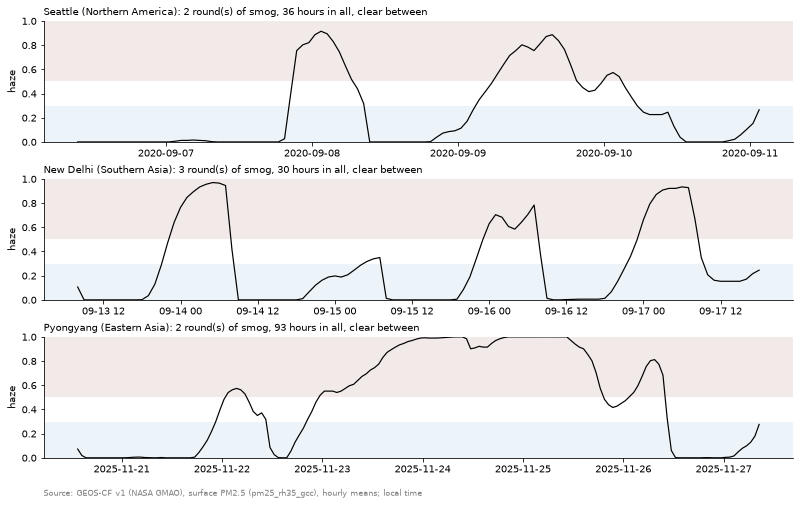

In [9]:
def utc_hour(index):
    return FIRST_HOUR + timedelta(hours=int(index))


fig, axes = plt.subplots(len(picks), 1, figsize=(11, 2.3 * len(picks)), constrained_layout=True)
for ax, p in zip(axes, picks.itertuples()):
    tz = ZoneInfo(p.tz)
    local = [utc_hour(p.first + h).astimezone(tz).replace(tzinfo=None) for h in range(len(p.haze))]
    ax.plot(local, p.haze, color="k", lw=1.2)
    ax.axhspan(SMOTHERED_ABOVE, 1, color="tab:brown", alpha=0.12, lw=0)
    ax.axhspan(0, CLEAR_BELOW, color="tab:blue", alpha=0.08, lw=0)
    ax.set_ylim(0, 1); ax.set_ylabel("haze")
    ax.set_title(f"{p.city} ({p.region}): {p.rounds} round(s) of smog, {p.smog_hours:.0f} hours in all, clear between",
                 loc="left", fontsize=10)
source_note(axes[-1], CREDIT + "; local time")
plt.show()

### 5.1 On the map

Each song at three hours: its first, its thickest (the box's highest haze) and its last.

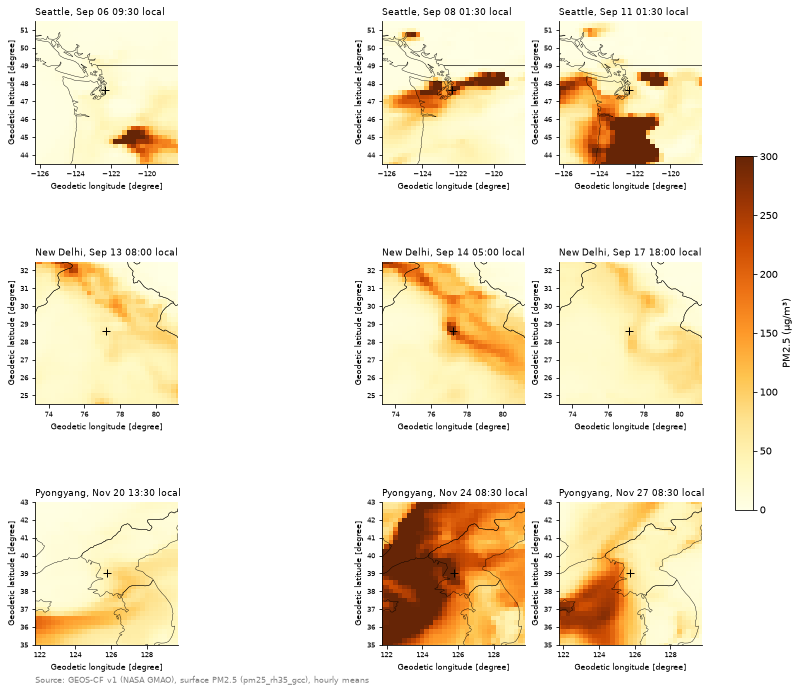

In [10]:
countries = gpd.read_file(download("natural_earth/ne_50m_admin_0_countries.zip",
                                   f"{NATURAL_EARTH_50M}/ne_50m_admin_0_countries.zip"))
fig, axes = plt.subplots(len(picks), 3, figsize=(11, 3.4 * len(picks)), constrained_layout=True)
for row, p in zip(axes, picks.itertuples()):
    r, k = cell(p.lat, p.lon)
    lats = (r - BOX + np.arange(2 * BOX + 1)) * GRID_DEG - 90
    lons = (k - BOX + np.arange(2 * BOX + 1)) * GRID_DEG - 180
    for ax, h in zip(row, (0, int(np.argmax(p.haze)), len(p.haze) - 1)):
        mesh = ax.pcolormesh(lons, lats, p.frames[h], cmap="YlOrBr", vmin=0, vmax=300, shading="nearest")
        countries.boundary.plot(ax=ax, color="k", linewidth=0.4)
        ax.plot(p.lon, p.lat, "k+", ms=8)
        ax.set_xlim(lons[0], lons[-1]); ax.set_ylim(lats[0], lats[-1]); ax.set_aspect("equal")
        when = utc_hour(p.first + h).astimezone(ZoneInfo(p.tz))
        ax.set_title(f"{p.city}, {when:%b %d %H:%M} local", fontsize=9, loc="left")
        ax.tick_params(labelsize=7)
fig.colorbar(mesh, ax=axes, shrink=0.5, label="PM2.5 (µg/m³)")
source_note(axes[-1, 0], CREDIT)
plt.show()

## 6. Track data

Each song becomes one CSV in `data/smog/tracks/`: a row per hour (`time`, in UTC), then each cell's PM2.5 rounded to whole µg/m³, south to north and west to east (a column per cell, named `<lat>_<lon>`). `tracks.json` gives the box, the city and the time zone the app shows the clock in.

In [11]:
if TRACKS.exists():
    for old in TRACKS.iterdir():
        old.unlink()
TRACKS.mkdir(parents=True, exist_ok=True)
MESSAGE = ("Though small particles typically remain in the atmosphere for only a few days, they can be transported far "
           "away from source regions by large scale weather systems.")

entries, summary = [], []
for p in picks.itertuples():
    r, k = cell(p.lat, p.lon)
    lats = (r - BOX + np.arange(2 * BOX + 1)) * GRID_DEG - 90
    lons = (k - BOX + np.arange(2 * BOX + 1)) * GRID_DEG - 180
    hours = [utc_hour(p.first + h) for h in range(len(p.frames))]
    file = f"{p.city.lower().replace(' ', '_')}_{hours[0]:%Y}.csv"
    table = pd.DataFrame(np.round(p.frames.reshape(len(hours), -1)).astype(int),
                         columns=[f"{lat:g}_{lon:g}" for lat in lats for lon in lons])
    table.insert(0, "time", [f"{t:%Y-%m-%dT%H:%MZ}" for t in hours])
    table.to_csv(TRACKS / file, index=False)
    entries.append({
        "file": file,
        "title": p.city,
        "pages": [{"svsId": 5151, "svsUrl": "https://svs.gsfc.nasa.gov/5151/", "message": MESSAGE}],
        "note": ("Ours: smog blown over the city and swept out again, picked by the app's rules and how fast its fog flows "
                 "(section 5); every hour of it."),
        "sources": [{
            "source": f"GEOS-CF v1 (NASA GMAO), aqc_tavg_1hr_g1440x721_v1, {VARIABLE}",
            "sourceUrl": "https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/",
            "downloadUrl": f"{OPENDAP}.dods?{VARIABLE}[{p.first}:{p.first + len(hours) - 1}][0][{r - BOX}:{r + BOX}][{k - BOX}:{k + BOX}]",
            "version": "v1",
            "doi": "https://doi.org/10.1029/2020MS002413",
            "downloaded": "2026-11-15",
            "license": "NASA data, no restrictions on use",
            "credit": ("Keller, C. A., et al. (2021). Description of the NASA GEOS composition forecast modeling system "
                       "GEOS-CF v1.0. JAMES 13, e2020MS002413."),
            "substitute": "EIC 5151 links GEOS-CF v2, which starts on 2025-08-04; v1 holds every song.",
        }],
        "city": {"name": p.city, "lat": p.lat, "lon": p.lon},
        "grid": {"south": float(lats[0]), "west": float(lons[0]), "stepDeg": GRID_DEG, "rows": len(lats), "cols": len(lons)},
        "timeZone": p.tz,
        "units": {"<lat>_<lon>": "µg/m³ (surface PM2.5 at 35 % relative humidity, hourly mean, the cell centred there)"},
        "timeRange": [table["time"].iloc[0], table["time"].iloc[-1]],
    })
    size = (TRACKS / file).stat().st_size
    assert size < 3e6, (file, size)
    tz = ZoneInfo(p.tz)
    summary.append({"song": p.city, "region": p.region, "file": file,
                    "local": f"{hours[0].astimezone(tz):%Y-%m-%d %H:%M} to {hours[-1].astimezone(tz):%m-%d %H:%M}",
                    "hours": len(hours), "rounds": p.rounds, "smog_hours": round(p.smog_hours), "change": round(p.change, 1),
                    "flow_kmh": round(p.flow_kmh, 1),
                    "KB": round(size / 1024)})
(TRACKS / "tracks.json").write_text(json.dumps(entries, indent=2, ensure_ascii=False) + "\n")
pd.DataFrame(summary).set_index("song")

,region,file,local,hours,rounds,smog_hours,change,flow_kmh,KB
song,,,,,,,,,
Seattle,Northern America,seattle_2020.csv,2020-09-06 09:30 to 09-11 01:30,113,2,36,3.6,18.5,333
New Delhi,Southern Asia,new_delhi_2025.csv,2025-09-13 08:00 to 09-17 18:00,107,3,30,3.4,33.8,356
Pyongyang,Eastern Asia,pyongyang_2025.csv,2025-11-20 13:30 to 11-27 08:30,164,2,93,3.3,13.1,599


## 7. Summary

| Item | Value |
| --- | --- |
| EIC page | [5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) |
| EIC message | Small particles stay in the air for a few days and are carried far from their sources by the weather |
| Candidates (ours) | 25 episodes of heavy PM2.5 in 10 regions, 2019–2025 |
| The rule (ours) | 100–170 hours from clear air to clear air, one to three rounds of smog by the app's own haze and turns, no stretch under 8 hours; the most change in the city's air per candidate; one per region, the three whose fog flows fastest (median shift of its pattern in 3 hours, km/h) |
| Tracks | The three songs in section 6: every hour of each, the 33 × 33 cells (0.25°, ±4°) around the city |
| What the app does with them | `src/features/tracks/domain/smog.js`: the fog, the turns, the pace (54 s a song); see [docs/albums/smog.md](../docs/albums/smog.md) |